# Solution A: sample-based SQD

**Grader energy: −108.902027 Ha** at 300 strings per spin.

Every string comes from simulated quantum samples, except 2 pinned reference strings per spin:

1. Sample the lab's LUCJ circuit with Qiskit Aer's matrix-product-state simulator: 100 000 shots, bond dimension 128
   (cached in `results/samples/shots100000/`).
2. Run the `qiskit-addon-sqd` loop (configuration recovery, batching, carry-over, spin symmetrisation) with the lab's
   100 reference strings pinned.
3. Rotate the orbitals with CASSCF for the fixed strings, then re-select strings from the sampled pool in the rotated
   basis, keeping half of them. Three short cycles, then five converged ones.


In [1]:
import json
import os
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt

from eval.score import score_result
from n2sqd.result import Result

# run from the repository root: the Hamiltonian cache and reference energies use paths relative to it
if Path.cwd().name == "notebooks":
    os.chdir("..")


def show_score(path):
    s = score_result(Result.load(path))
    print(f"grader energy         {s.energy:.6f} Ha")
    print(f"strings per spin      {s.dims[0]} / {s.dims[1]}")
    print(f"claim check passes    {s.matches}")
    print(f"official grader code  {s.grader_energy} Ha (agrees: {s.grader_agrees})")
    print(f"gap to exact          {s.gap_to_reference_mha:+.1f} mHa ({s.reference_label})")
    print(f"vs CCSD               {-s.below_ccsd_mha:+.1f} mHa")
    return s


def chain_energies(files):
    """Energy after the start of each run and after every completed cycle, from the logged metrics."""
    labels, energies = [], []
    for file in files:
        metrics = json.loads(Path(file).read_text())
        run = Path(file).stem
        for event in metrics["events"]:
            phase = event["phase"]
            if phase in ("refine-0", "sqd-0") or phase.startswith("cycle-"):
                labels.append(f"{run} start" if phase in ("refine-0", "sqd-0") else f"{run} cycle {phase[6:]}")
                energies.append(event["energy"])
    return labels, energies


def plot_chain(labels, energies, title):
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(range(len(energies)), energies, marker="o")
    ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right", fontsize=8)
    ax.set_ylabel("energy / Ha")
    ax.ticklabel_format(axis="y", useOffset=False)
    ax.set_title(title)
    plt.tight_layout()
    plt.show()


## Score the committed result

The same validation and energy code as the official grader, run offline (under 2 minutes).

In [2]:
score = show_score("results/best/track-a/result.npz")

Recomputing the energy of best_subspace (up to two minutes)...


grader energy         -108.902027 Ha
strings per spin      300 / 300
claim check passes    True
official grader code  -108.902027 Ha (agrees: True)
gap to exact          +80.0 mHa (DMRG extrapolated (estimate))
vs CCSD               +7.5 mHa


## How the run converged

Energy after the SQD loop (`sqd`) and after each orbital-optimisation ↔ re-selection cycle (`oo`, then the converged `deep-oo`).

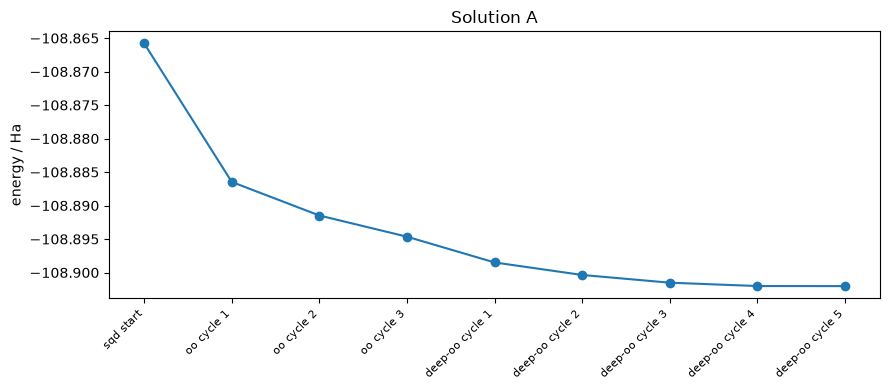

distinct valid sampled strings: 4110 alpha, 5126 beta
final strings found in the raw shots: 298 alpha, 298 beta (of 300)


In [3]:
labels, energies = chain_energies([
    "results/best/track-a/runs/sqd.json",
    "results/best/track-a/runs/oo.json",
    "results/best/track-a/runs/deep-oo.json",
])
plot_chain(labels, energies, "Solution A")
pool = json.loads(Path("results/best/track-a/runs/deep-oo.json").read_text())["pool_statistics"]
print(f"distinct valid sampled strings: {pool['raw_valid_unique_alpha']} alpha, {pool['raw_valid_unique_beta']} beta")
print(f"final strings found in the raw shots: {pool['final_alpha_in_raw']} alpha, {pool['final_beta_in_raw']} beta (of 300)")

## Reproduce from scratch

About 3.5 h on an M4 laptop. Set `RUN_FULL = True` to run it.

In [4]:
RUN_FULL = False

CHAIN = [
    "-m n2sqd.tracka --out output/solution-a/sqd --samples results/samples/shots100000/samples_bd128_s142.npz --samples-per-batch 1000 --num-batches 5 --max-iterations 10 --pinned-reference 100 --oo-cycles 0",
    "-m n2sqd.tracka --out output/solution-a/oo --samples results/samples/shots100000/samples_bd128_s142.npz --samples-per-batch 1000 --num-batches 5 --max-iterations 6 --start file:output/solution-a/sqd/result.npz --pinned-reference 100 --oo-cycles 3 --oo-macro 10 --reselect sqd --carry-fraction 0.5",
    "-m n2sqd.tracka --out output/solution-a/deep-oo --samples results/samples/shots100000/samples_bd128_s142.npz --samples-per-batch 1000 --num-batches 5 --max-iterations 6 --start file:output/solution-a/oo/result.npz --orbitals file:output/solution-a/oo/orbitals.npy --pinned-reference 100 --oo-cycles 6 --oo-macro 60 --reselect sqd --carry-fraction 0.5 --seed 342",
]

if RUN_FULL:
    from n2sqd.baselines import get_samples
    from n2sqd.hamiltonian import load_or_build

    get_samples(load_or_build(), Path("results/samples/shots100000"), 128, 100000, 142)  # cached: returns at once
    for args in CHAIN:
        subprocess.run([sys.executable, *args.split()], check=True)
    show_score("output/solution-a/deep-oo/result.npz")
else:
    print("RUN_FULL is False. The chain:")
    print("\n".join("python " + args for args in CHAIN))

RUN_FULL is False. The chain:
python -m n2sqd.tracka --out output/solution-a/sqd --samples results/samples/shots100000/samples_bd128_s142.npz --samples-per-batch 1000 --num-batches 5 --max-iterations 10 --pinned-reference 100 --oo-cycles 0
python -m n2sqd.tracka --out output/solution-a/oo --samples results/samples/shots100000/samples_bd128_s142.npz --samples-per-batch 1000 --num-batches 5 --max-iterations 6 --start file:output/solution-a/sqd/result.npz --pinned-reference 100 --oo-cycles 3 --oo-macro 10 --reselect sqd --carry-fraction 0.5
python -m n2sqd.tracka --out output/solution-a/deep-oo --samples results/samples/shots100000/samples_bd128_s142.npz --samples-per-batch 1000 --num-batches 5 --max-iterations 6 --start file:output/solution-a/oo/result.npz --orbitals file:output/solution-a/oo/orbitals.npy --pinned-reference 100 --oo-cycles 6 --oo-macro 60 --reselect sqd --carry-fraction 0.5 --seed 342
